## Question $3$

Build a model integrate-and-fire neuron from equation 5.8. Use Vrest = 70mV, Rm = 10M ,and m =10ms. Initially set V = Vrest.
When the membrane potential reaches Vth = -54 mV, make the neuron fire a spike and reset the potential to Vreset = 80 mV. Show sample voltage traces (with spikes) for a 300-ms-long current pulse (choose a reasonable current Ie) centered in a 500-ms-long simulation. Determine the firing rate of the model for various magnitudes of constant Ie and compare the results with equation 5.11.

In [23]:
import matplotlib.pyplot as plt
from math import *

Exemple pour un courant injecté de 2 mA :

In [24]:
def I_e(t):
    if t >= 100 and t <= 400 :
        return 2
    else :
        return 0

L'équation $5.8$ du livre donne :

In [25]:
def f(t,y,V_rest,τ_m,R_m,I_e,): # dérivée de V
    return (V_rest - y)/τ_m + (R_m*I_e(t))/τ_m

L'approximation de V donne :

In [29]:
def Euler_O1(t_0,y_0,h,T,V_reset,V_th,V_rest,τ_m,R_m):
    Images_Euler = [y_0]
    Atcd_Euler = [t_0]
    y = y_0
    t = t_0
    spike = 0
    for i in range (int((T-t_0)/h)):
        if y>=V_th :
           y = V_reset
           spike += 1
        else : 
            y = h * f(t,y,V_rest,τ_m,R_m,I_e) + y  
        t += h
        Images_Euler.append(y)
        Atcd_Euler.append(t)
    r_isi = spike / (300*10**(-3)) # comme courant injecté pendant 300ms
    return Atcd_Euler,Images_Euler,r_isi

In [30]:
def graph_O1(t_0,y_0,h,T,V_reset,V_th,V_rest,τ_m,R_m):
    Atcd_Euler,Images_Euler,r_isi = Euler_O1(t_0,y_0,h,T,V_reset,V_th,V_rest,τ_m,R_m)
    plt.figure(figsize =(8,6))
    plt.plot(Atcd_Euler,Images_Euler, label = "Euler", color = "blue" )
    plt.xlabel("t (ms)")
    plt.ylabel("V(mV)")
    plt.legend()
    plt.show()

Exemple avec les valeurs de l'énoncé :

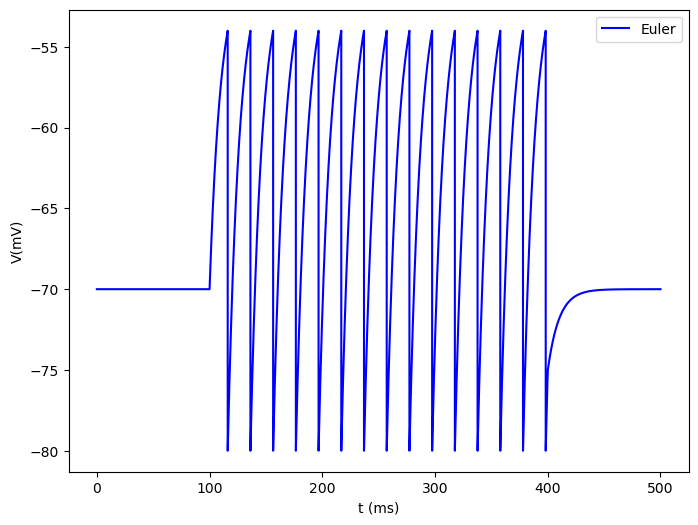

In [31]:
Atcd_Euler,Images_Euler,r_isi = Euler_O1(0,-70,0.01,500,-80,-54,-70,10,10)
graph_O1(0,-70,0.01,500,-80,-54,-70,10,10)

L'équation $5.11$ donne :

In [39]:
def r_isi_theorique(V_reset,V_th,V_rest,τ_m,R_m,I):
    return 10**3*(τ_m *log((R_m*I +V_rest-V_reset)/(R_m*I +V_rest-V_th)))**(-1)

Ce qui donne pour un courant injecté de 2 mA :

In [40]:
r_isi_theorique = r_isi_theorique(-80,-54,-70,10,10,2)
print (r_isi_theorique)

49.630180202463194


On peut comparer le taux de décharge interspike trouvé et celui théorique :

In [41]:
r_isi_théorique - r_isi

-0.36981979753680605